# Controllability of HCP structural connectomes

Average, modal and boundary controllability (Gu et al., *Nat Commun* 2015) in discrete and continuous time, for the
group connectome and every subject, summarised as Gu et al. did: each subject's values are ranked across nodes and
the ranks are averaged across subjects. The results are compared with those Gu et al. report.

- **Data:** `data/connectivity/<dataset>/` at the repository's root (not in the repository; see `README.md`).
- **Partition for boundary controllability:** the Yeo 7 systems of the Schaefer 400 parcellation (Gu et al. used
  data-driven communities), with Gu et al.'s `rho = 0.2`.
- **Outputs:** `results/new_features/hcp_controllability/` (git-ignored: derived from the data).
- **Environment:** nctpy (with the `plot` extra) and snaplab_tools.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.stats import rankdata
from threadpoolctl import threadpool_limits

from nctpy.metrics import ave_control, boundary_control, modal_control
from nctpy.plotting import reg_plot, set_plotting_params
from nctpy.utils import matrix_normalization
from snaplab_tools.datasets import schaefer_systems
from snaplab_tools.stats import compute_stat

set_plotting_params()

In [2]:
# settings
dataset = "HCP-YA"  # or "HCP-D"
n_jobs = 16  # subjects computed in parallel
n_subjects = None  # None for all subjects; a small number for a quick check

PROJECT = Path.cwd().resolve().parents[1]  # this notebook lives in scripts/new_features/
out_dir = PROJECT / "results" / "new_features" / "hcp_controllability"
out_dir.mkdir(parents=True, exist_ok=True)

SYSTEMS = ("discrete", "continuous")
METRICS = {"ac": "average controllability", "mc": "modal controllability", "bc": "boundary controllability"}
RHO = 0.2
GU_2015 = {"ac": 0.91, "mc": -0.99, "bc": 0.13}  # Gu et al. Fig. 2: r between mean ranks of weighted degree and each metric

## Data

Subjects without a connectome are left out. The Yeo systems come from snaplab_tools, in Schaefer order.

In [3]:
folder = PROJECT / "data" / "connectivity" / dataset
stem = f"{dataset}_Schaefer4007_"
manifest = pd.read_csv(folder / f"{stem}connectivity_manifest.csv", dtype={"subject": str})
A_all = np.load(folder / f"{stem}adjacency_matrices.npy", mmap_mode="r")
group = np.load(folder / f"{stem}adjacency_mean.npy")
subjects = np.flatnonzero(manifest["has_connectivity"].to_numpy())[:n_subjects]
partition = schaefer_systems(400)
print(f"{dataset}: {len(subjects)} subjects with a connectome; {group.shape[0]} nodes")

HCP-YA: 161 subjects with a connectome; 400 nodes


## Controllability metrics

For each connectome: node strength, and the three metrics in both time systems. Average and modal controllability
take the connectome normalised with nctpy's default (`c = 1`); boundary controllability takes it as measured and
normalises it itself, as Gu et al.'s code does.

In [4]:
def node_metrics(A):
    out = {"strength": A.sum(axis=0)}
    for system in SYSTEMS:
        A_norm = matrix_normalization(A, system=system, c=1)
        out[f"ac_{system}"] = ave_control(A_norm, system=system)
        out[f"mc_{system}"] = modal_control(A_norm, system=system)
        out[f"bc_{system}"] = boundary_control(A, partition, system=system, rho=RHO)
    return out


def subject_metrics(A):
    with threadpool_limits(1):  # one thread per worker; the parallelism is across subjects
        return node_metrics(A)


group_values = node_metrics(group)
per_subject = Parallel(n_jobs=n_jobs)(delayed(subject_metrics)(np.array(A_all[:, :, i])) for i in subjects)
keys = list(group_values)
subject_values = {k: np.stack([s[k] for s in per_subject]) for k in keys}  # (n_subjects, n_nodes)

# Gu et al.'s summary: rank each subject's values across nodes (ties share the average rank), then average
ranked = {k: np.mean([rankdata(v) for v in subject_values[k]], axis=0) for k in keys}

## Comparison with Gu et al.

Pearson correlations between the subject-averaged ranks of strength and of each metric, as in Gu et al.'s Fig. 2,
and between average and modal controllability.

In [5]:
rows = []
for system in SYSTEMS:
    row = {"system": system}
    for m in METRICS:
        row[f"{m.upper()} vs strength"] = compute_stat(ranked["strength"], ranked[f"{m}_{system}"], "pearson")[0]
    row["AC vs MC"] = compute_stat(ranked[f"ac_{system}"], ranked[f"mc_{system}"], "pearson")[0]
    rows.append(row)
rows.append({"system": "Gu et al. 2015", **{f"{m.upper()} vs strength": GU_2015[m] for m in METRICS}})
with_strength = pd.DataFrame(rows).set_index("system").round(2)
with_strength

,AC vs strength,MC vs strength,BC vs strength,AC vs MC
system,,,,
discrete,0.68,-0.96,0.20,-0.68
continuous,0.96,-0.96,0.21,-1.00
Gu et al. 2015,0.91,-0.99,0.13,NaN


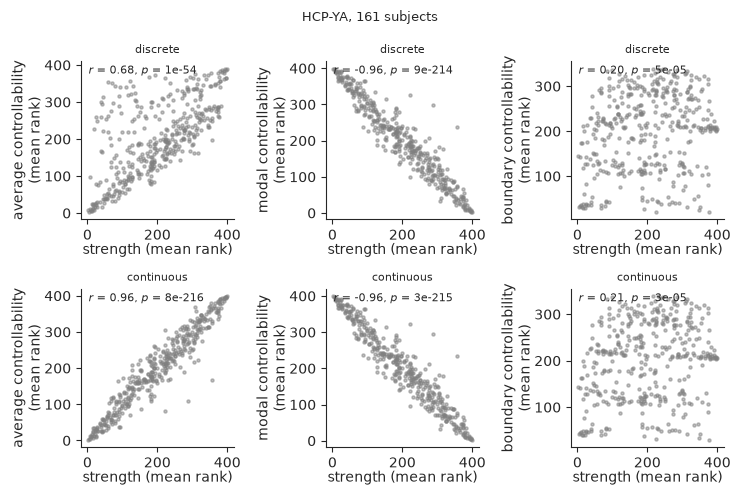

In [6]:
f, ax = plt.subplots(len(SYSTEMS), len(METRICS), figsize=(7.5, 5))
for i, system in enumerate(SYSTEMS):
    for j, (m, name) in enumerate(METRICS.items()):
        reg_plot(ranked["strength"], ranked[f"{m}_{system}"], "strength (mean rank)", f"{name}\n(mean rank)",
                 ax[i, j], regr_line=False, kde=False)
        ax[i, j].set_title(system, fontsize=8)
f.suptitle(f"{dataset}, {len(subjects)} subjects", fontsize=9)
f.tight_layout()
f.savefig(out_dir / f"{dataset}_ranked_vs_strength.png", dpi=200)
plt.show()

## Discrete vs continuous time

Pearson correlations between the two time systems: across nodes of the subject-averaged values ("regional"), across
subjects of the node-averaged values ("individual", as in Karrer et al. 2020), and of the subject-averaged ranks.

In [7]:
rows = []
for m in METRICS:
    d, c = subject_values[f"{m}_discrete"], subject_values[f"{m}_continuous"]
    rows.append({
        "metric": m.upper(),
        "regional": compute_stat(d.mean(0), c.mean(0), "pearson")[0],
        "individual": compute_stat(d.mean(1), c.mean(1), "pearson")[0],
        "mean ranks": compute_stat(ranked[f"{m}_discrete"], ranked[f"{m}_continuous"], "pearson")[0],
    })
time_systems = pd.DataFrame(rows).set_index("metric").round(3)
time_systems

,regional,individual,mean ranks
metric,,,
AC,0.883,-0.877,0.689
MC,0.999,0.999,1.000
BC,0.999,1.000,0.998


Discrete-time average controllability sums the system's response over an infinite horizon, so it depends on how
close the normalised system is to marginal stability. With `c = 1` and a connectome whose spectral radius is large
(as here, where the weights are large), the discrete normalised system's spectral radius is close to 1, and average
controllability is dominated by the slowest mode: it follows the squared leading eigenvector. This depends on the
connectome. Continuous-time average controllability uses a finite horizon (`T = 1`) and is not affected.

In [8]:
lam, V = np.linalg.eigh(group)
radius = lam[-1] / (1 + lam[-1])
print(f"group connectome: spectral radius {lam[-1]:.3g}; discrete normalised spectral radius {radius:.6f}")
print(f"group discrete AC vs 1 + v1^2 / (1 - r^2): Pearson "
      f"{compute_stat(group_values['ac_discrete'], 1 + V[:, -1] ** 2 / (1 - radius**2), 'pearson')[0]:.4f}")

group connectome: spectral radius 7.01e+04; discrete normalised spectral radius 0.999986
group discrete AC vs 1 + v1^2 / (1 - r^2): Pearson 1.0000


## Group connectome vs subjects

Spearman correlations between each metric on the group connectome and the subject-averaged ranks.

In [9]:
group_vs_subjects = pd.DataFrame(
    {system: {m.upper(): compute_stat(group_values[f"{m}_{system}"], ranked[f"{m}_{system}"], "spearman")[0]
              for m in METRICS} for system in SYSTEMS}
).round(3)
group_vs_subjects

,discrete,continuous
AC,0.973,0.999
MC,0.999,0.999
BC,0.879,0.807


## Save

Node-level values for the group and every subject, and the summary tables, to the git-ignored results folder.

In [10]:
np.savez(
    out_dir / f"{dataset}_controllability.npz",
    subjects=subjects,
    **{f"group_{k}": v for k, v in group_values.items()},
    **{f"subjects_{k}": v for k, v in subject_values.items()},
)
summary = {
    "dataset": dataset, "n_subjects": int(len(subjects)), "rho": RHO, "partition": "Yeo 7 systems",
    "with_strength": with_strength.to_dict(), "time_systems": time_systems.to_dict(),
    "group_vs_subjects": group_vs_subjects.to_dict(),
}
(out_dir / f"{dataset}_summary.json").write_text(json.dumps(summary, indent=2, default=float))
print(f"saved to {out_dir.relative_to(PROJECT)}")

saved to results/new_features/hcp_controllability
